In [1]:
import celloracle as co
co.check_python_requirements()

,package_name,installed_version,required_version,requirement_satisfied
0,numpy,1.26.4,auto,True
1,scipy,1.11.4,auto,True
2,cython,3.1.1,auto,True
3,numba,0.58.1,0.50.1,True
4,matplotlib,3.6.3,auto,True
5,seaborn,0.13.2,auto,True
6,scikit-learn,1.7.0,auto,True
7,h5py,3.13.0,3.1.0,True
8,pandas,1.5.3,1.0.3,True
9,velocyto,0.17.17,0.17,True


In [ ]:
import scanpy as sc
import pandas as pd
import anndata as ad
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

os.environ["CUDA_VISIBLE_DEVICES"] = "0" 

In [3]:
import celloracle as co
co.__version__

'0.20.0'

In [41]:
# visualization settings
%config InlineBackend.figure_format = 'retina'
%matplotlib inline

plt.rcParams['figure.figsize'] = [6, 4.5]
plt.rcParams["savefig.dpi"] = 300
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

In [7]:
os.chdir('/data_hdd4/yuseong/cancer_aging/analysis/h.github/Fig4')

In [8]:
save_folder = "figures/celloracleMal"
os.makedirs(save_folder, exist_ok=True)

In [58]:
#### LOAD ANNDATA

In [22]:
adata = sc.read_h5ad('data/4f/sc_mal_for_celloracle.h5ad')

In [23]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
adata = adata[:, adata.var['highly_variable']].copy()

In [72]:
### RUN CELLORACLE

In [24]:
base_GRN = pd.read_parquet('data/4f/base_GRN_dataframe.parquet')

In [25]:
base_GRN

,peak_id,gene_short_name,9430076C15RIK,AC002126.6,AC012531.1,AC226150.2,AFP,AHR,AHRR,AIRE,...,ZNF784,ZNF8,ZNF816,ZNF85,ZSCAN10,ZSCAN16,ZSCAN22,ZSCAN26,ZSCAN31,ZSCAN4
0,chr10_100009743_100010244,DNMBP,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,chr10_100081652_100082153,CPN1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
2,chr10_100185812_100186313,ERLIN1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,chr10_100186342_100186843,ERLIN1,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,chr10_100229354_100229855,CHUK,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41367,chrX_9785550_9786051,SHROOM2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41368,chrX_9786109_9786610,SHROOM2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41369,chrX_9911033_9911534,SHROOM2,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
41370,chrX_9911535_9912036,SHROOM2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [26]:
len(base_GRN.columns)

1095

In [27]:
len(base_GRN.gene_short_name.unique())

21390

In [28]:
oracle = co.Oracle()

In [29]:
# Check data in anndata
print("Metadata columns :", list(adata.obs.columns))
print("Dimensional reduction: ", list(adata.obsm.keys()))

Metadata columns : ['orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Sample', 'percent.mt', 'RNA_snn_res.1', 'seurat_clusters', 'condition', 'origin', 'CellType', 'barcode', 'copykat_nonref', 'EMT', 'ECM', 'SEN_MAYO', 'CELLULAR.RESPONSE.TO.UV', 'RESPONSE.TO.UV', 'MEblue', 'umap_1', 'umap_2', 'Patient', 'tissue', 'treatment', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'SAMPLE', 'n_counts', 'velocity_self_transition', 'leiden', 'sen_cluster', 'latent_time', 'clusters']
Dimensional reduction:  ['X_umap']


In [46]:
# # In this notebook, we use the unscaled mRNA count for the input of Oracle object.
adata.X = adata.layers["counts"].copy()

# Instantiate Oracle object.
oracle.import_anndata_as_raw_count(adata=adata,
                                   cluster_column_name="clusters",
                                   embedding_name="X_umap")

In [47]:
# You can load TF info dataframe with the following code.
oracle.import_TF_data(TF_info_matrix=base_GRN)

# Alternatively, if you saved the informmation as a dictionary, you can use the code below.
# oracle.import_TF_data(TFdict=TFinfo_dictionary)

In [49]:
# Perform PCA
oracle.perform_PCA()

# # Select important PCs
# plt.plot(np.cumsum(oracle.pca.explained_variance_ratio_)[:100])
n_comps = np.where(np.diff(np.diff(np.cumsum(oracle.pca.explained_variance_ratio_))>0.002))[0][0]
# plt.axvline(n_comps, c="k")
# plt.show()
# print(n_comps)
n_comps = min(n_comps, 50)

In [50]:
n_cell = oracle.adata.shape[0]
print(f"cell number is :{n_cell}")

cell number is :1156


In [51]:
k = int(0.025*n_cell)
print(f"Auto-selected k is :{k}")

Auto-selected k is :28


In [52]:
oracle.knn_imputation(n_pca_dims=n_comps, k=k, balanced=True, b_sight=k*8,
                      b_maxl=k*4, n_jobs=4)

In [ ]:
oracle.to_hdf5("data/4f/singlecell_mal_hg38.celloracle.oracle")

In [54]:
# %%time
# Calculate GRN for each population in "louvain_annot" clustering unit.
# This step may take some time.(~30 minutes)
links = oracle.get_links(cluster_name_for_GRN_unit="clusters", alpha=10,
                         verbose_level=10, n_jobs = 30)

  0%|          | 0/10 [00:00<?, ?it/s]

Inferring GRN for C0...


  0%|          | 0/2149 [00:00<?, ?it/s]

Inferring GRN for C1...


  0%|          | 0/2149 [00:00<?, ?it/s]

Inferring GRN for C2...


... (11 outputs left out)

Inferring GRN for C8...


  0%|          | 0/2149 [00:00<?, ?it/s]

Inferring GRN for C9...


  0%|          | 0/2149 [00:00<?, ?it/s]

In [55]:
links.links_dict.keys()

dict_keys(['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9'])

In [ ]:
links.to_hdf5(file_path="data/4f/links.mal_hg38.celloracle.links")

In [ ]:
### CHECK GRN OUTPUTS

In [30]:
links = co.load_hdf5(file_path="data/4f/links.mal_hg38.celloracle.links")

In [31]:
# The raw network data is stored in the links_dict attribute, while the filtered network data is stored in the filtered_links attribute.
links.filter_links(p=0.05, weight="coef_abs", threshold_number=3000)

In [32]:
plt.rcParams["figure.figsize"] = [9, 4.5]

C0


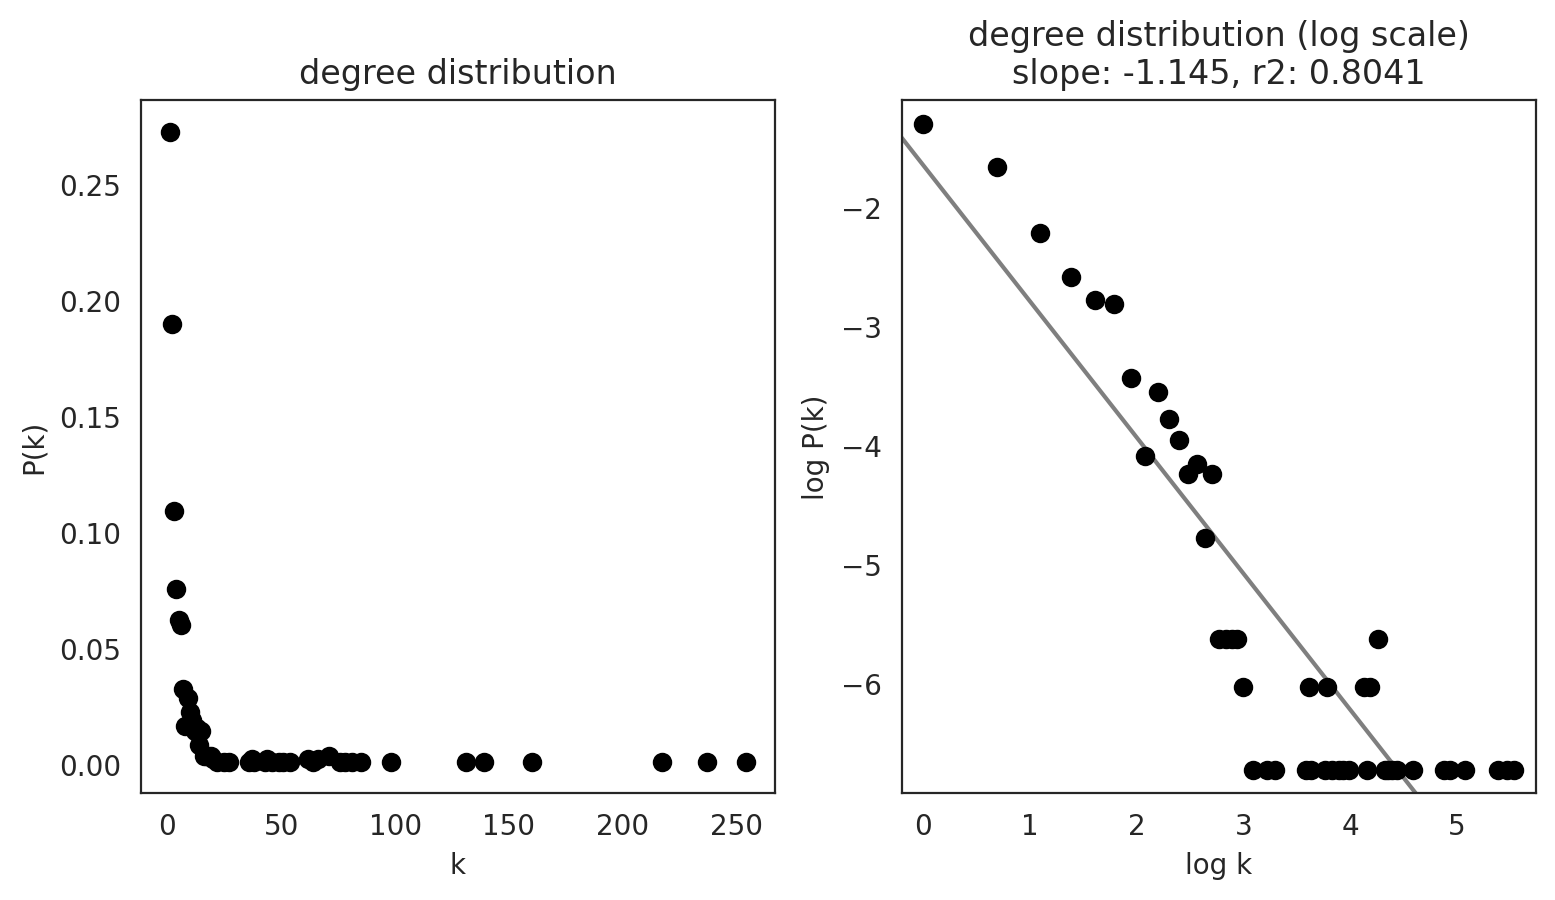

C1


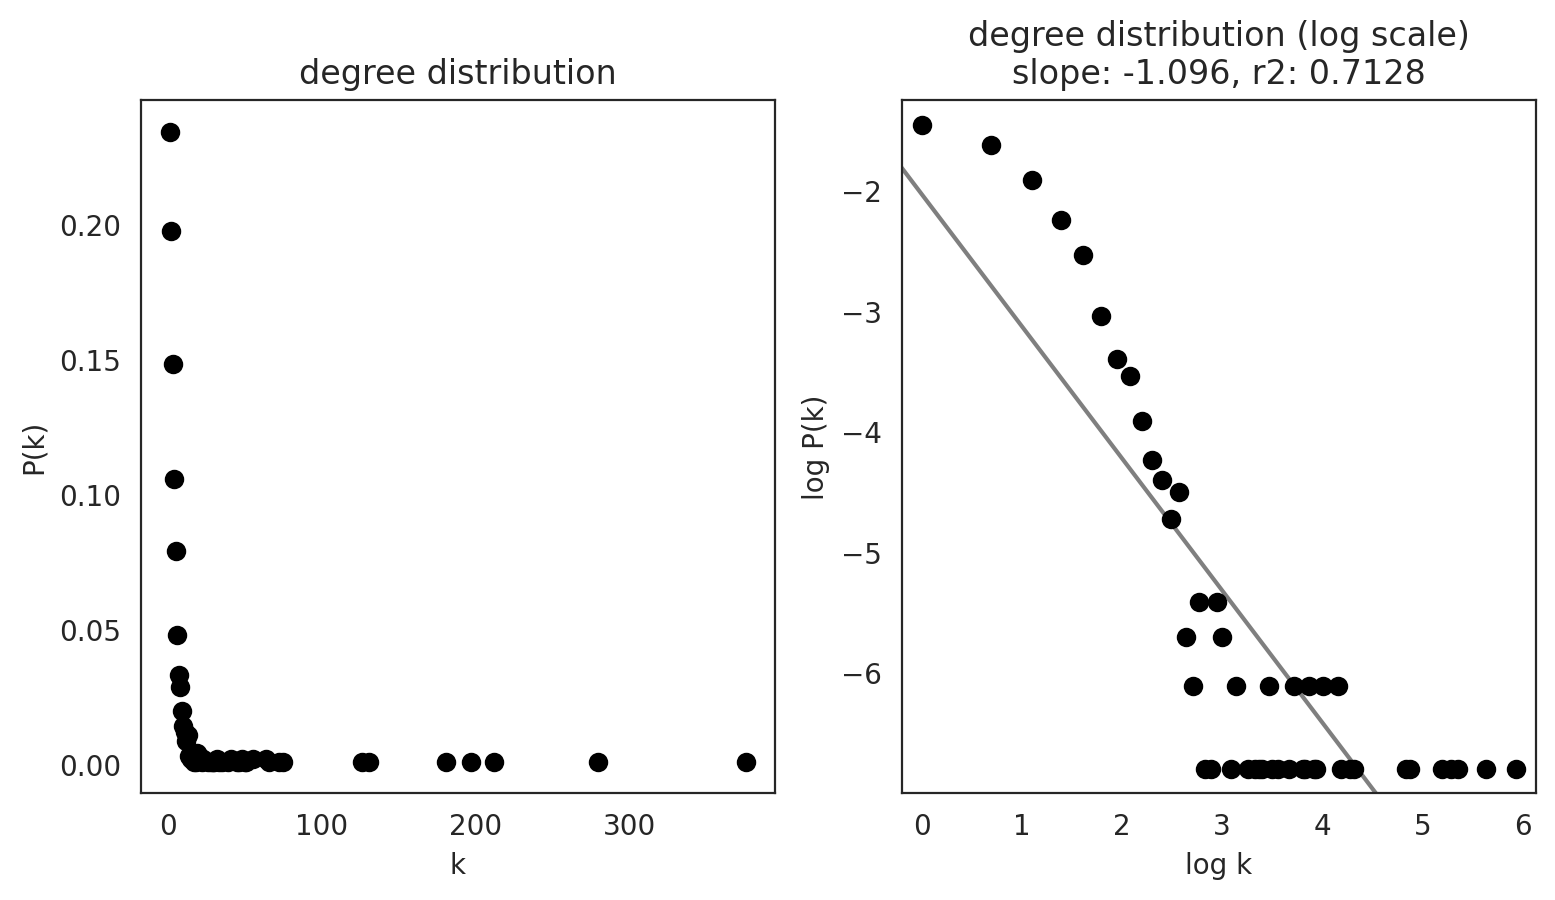

C2


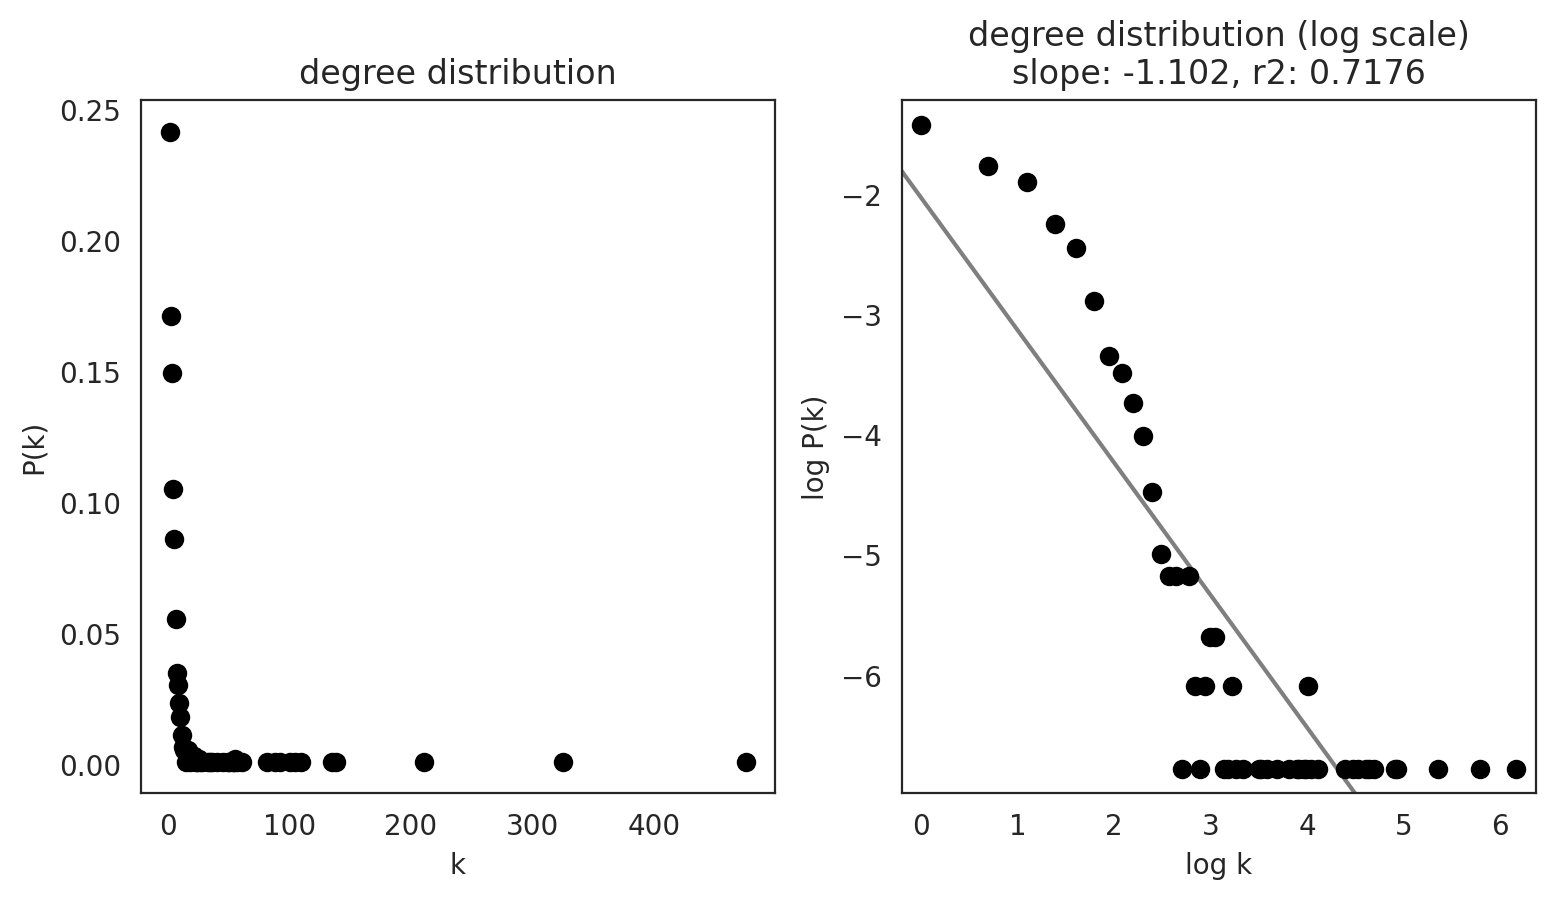

C3


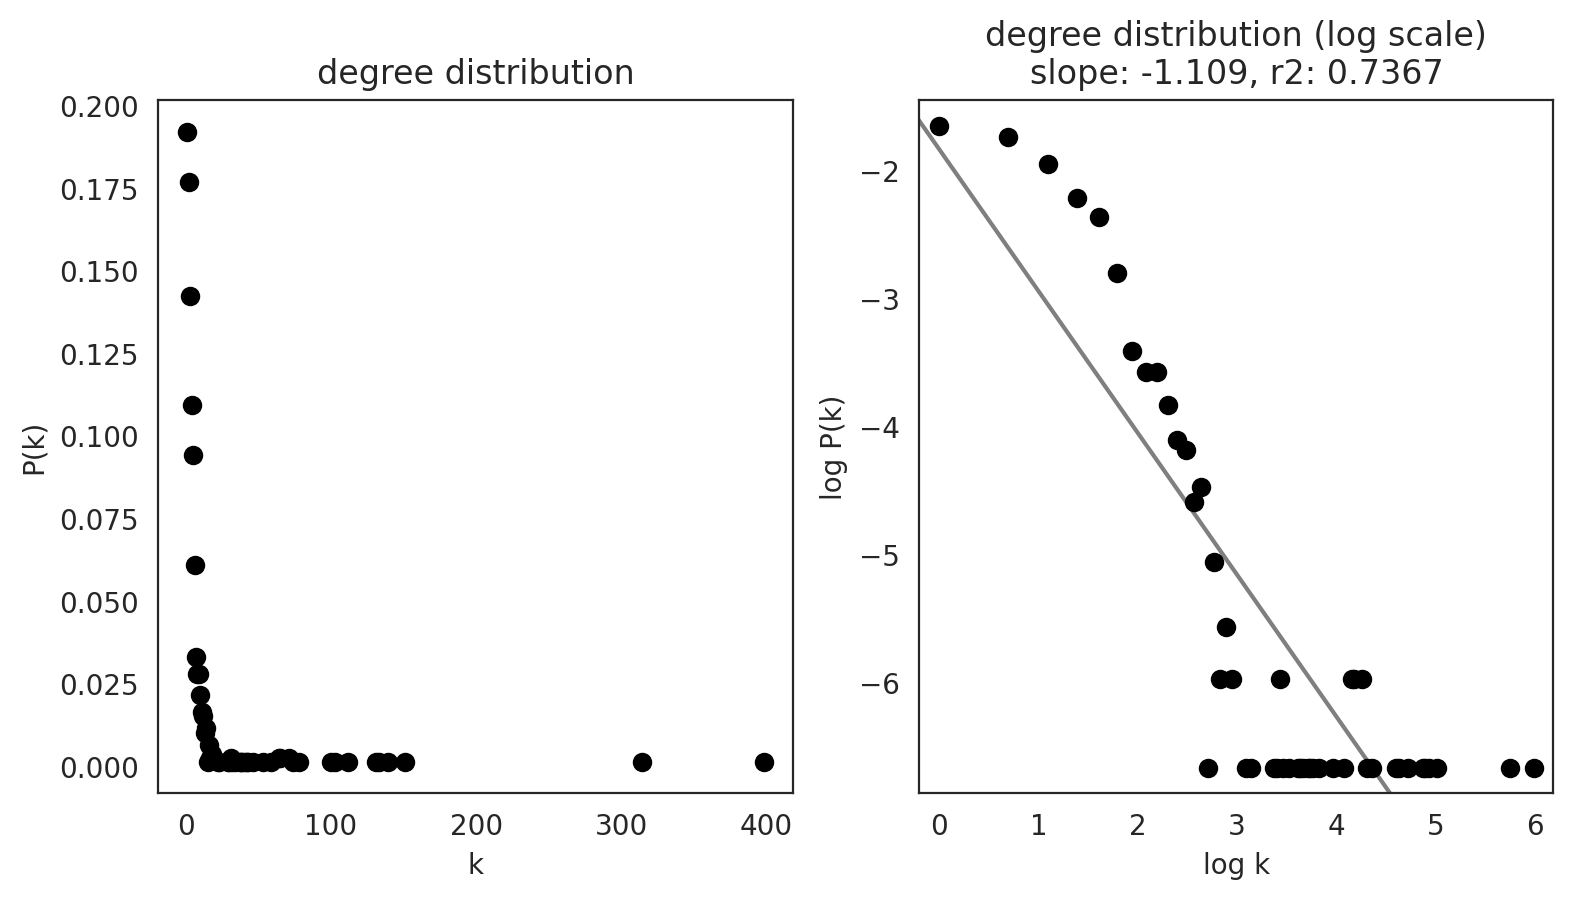

C4


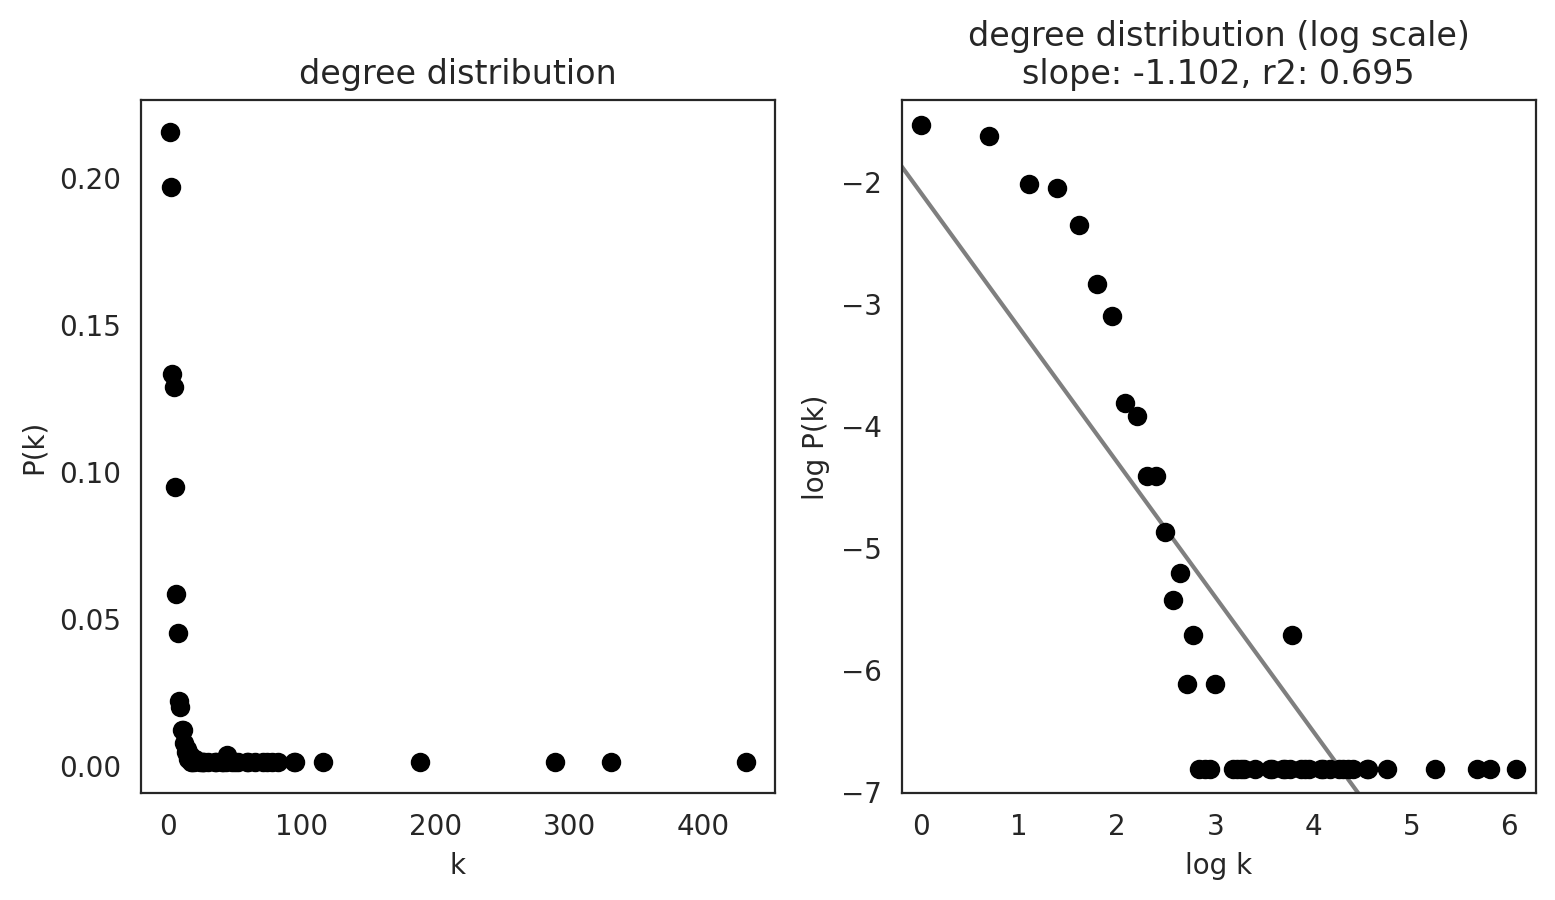

C5


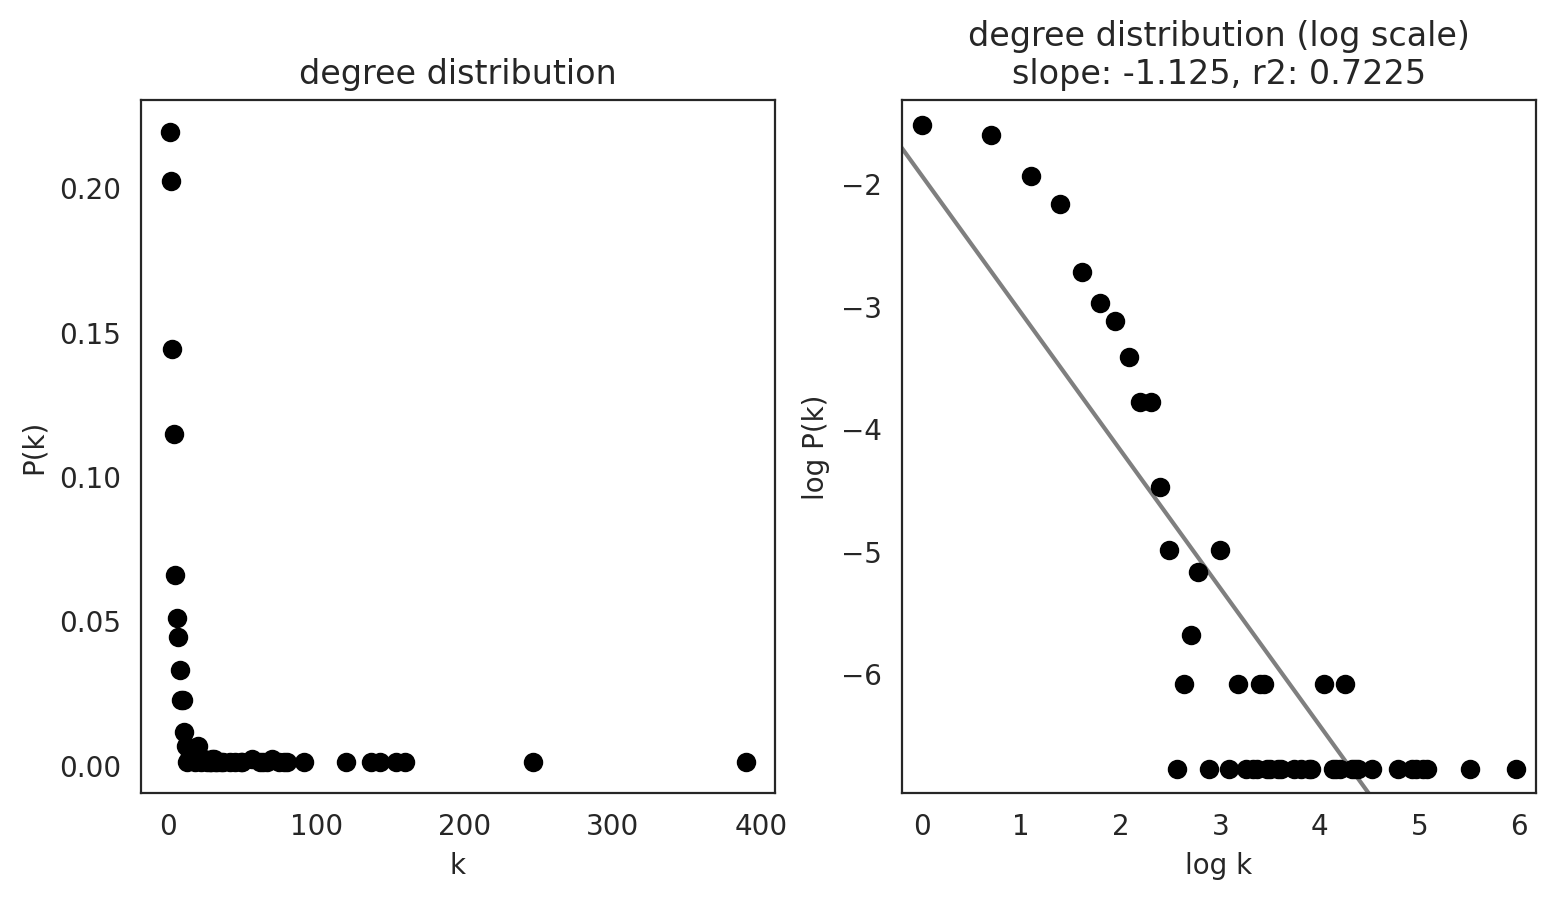

C6


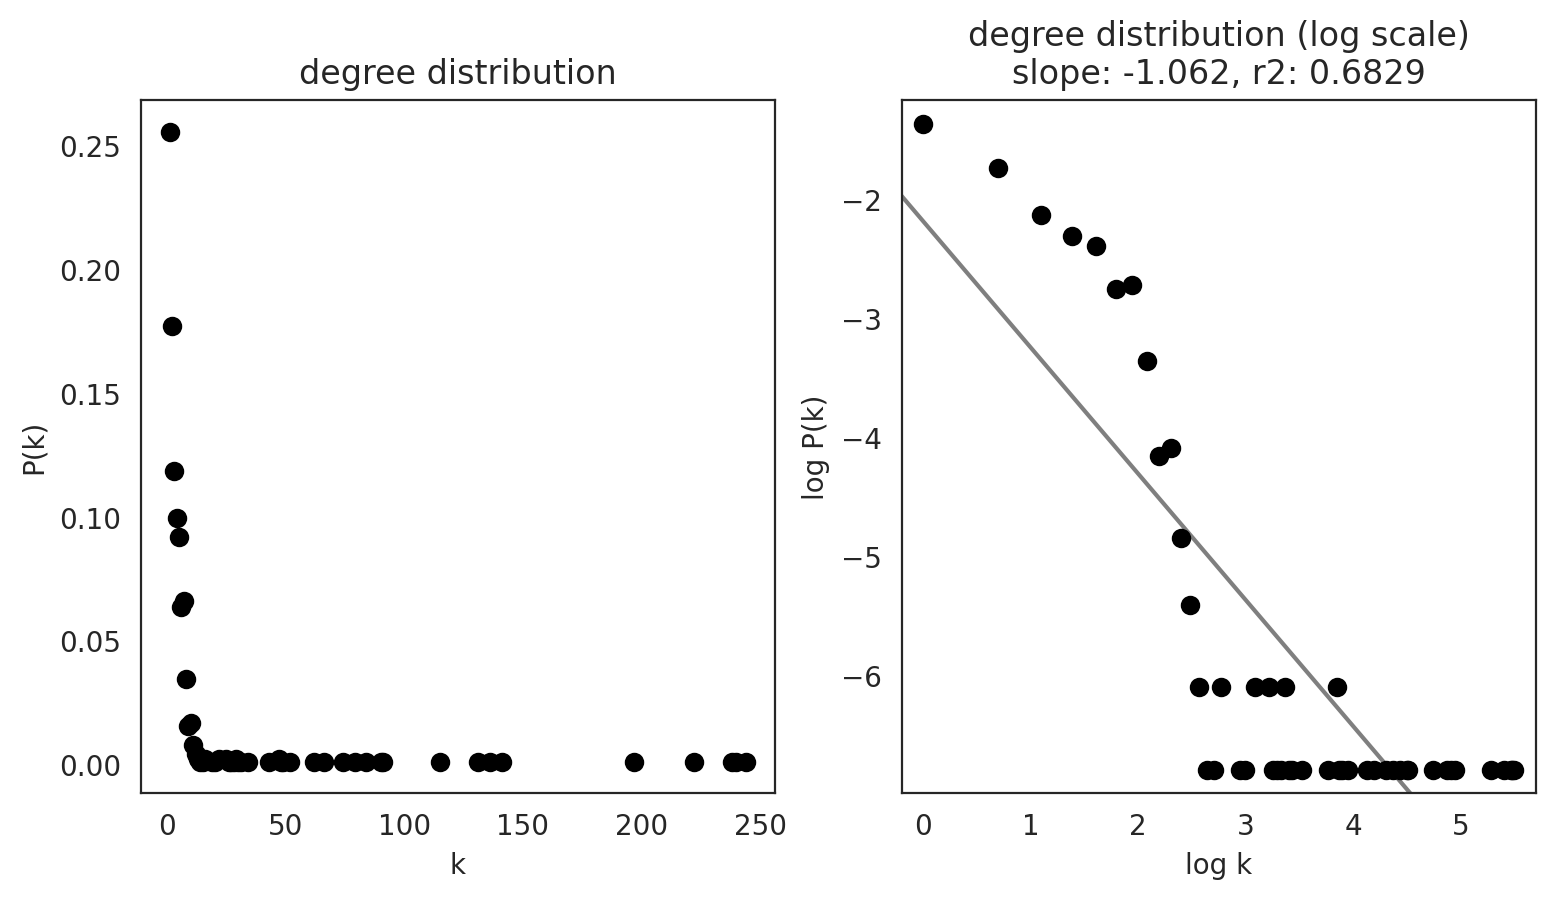

C7


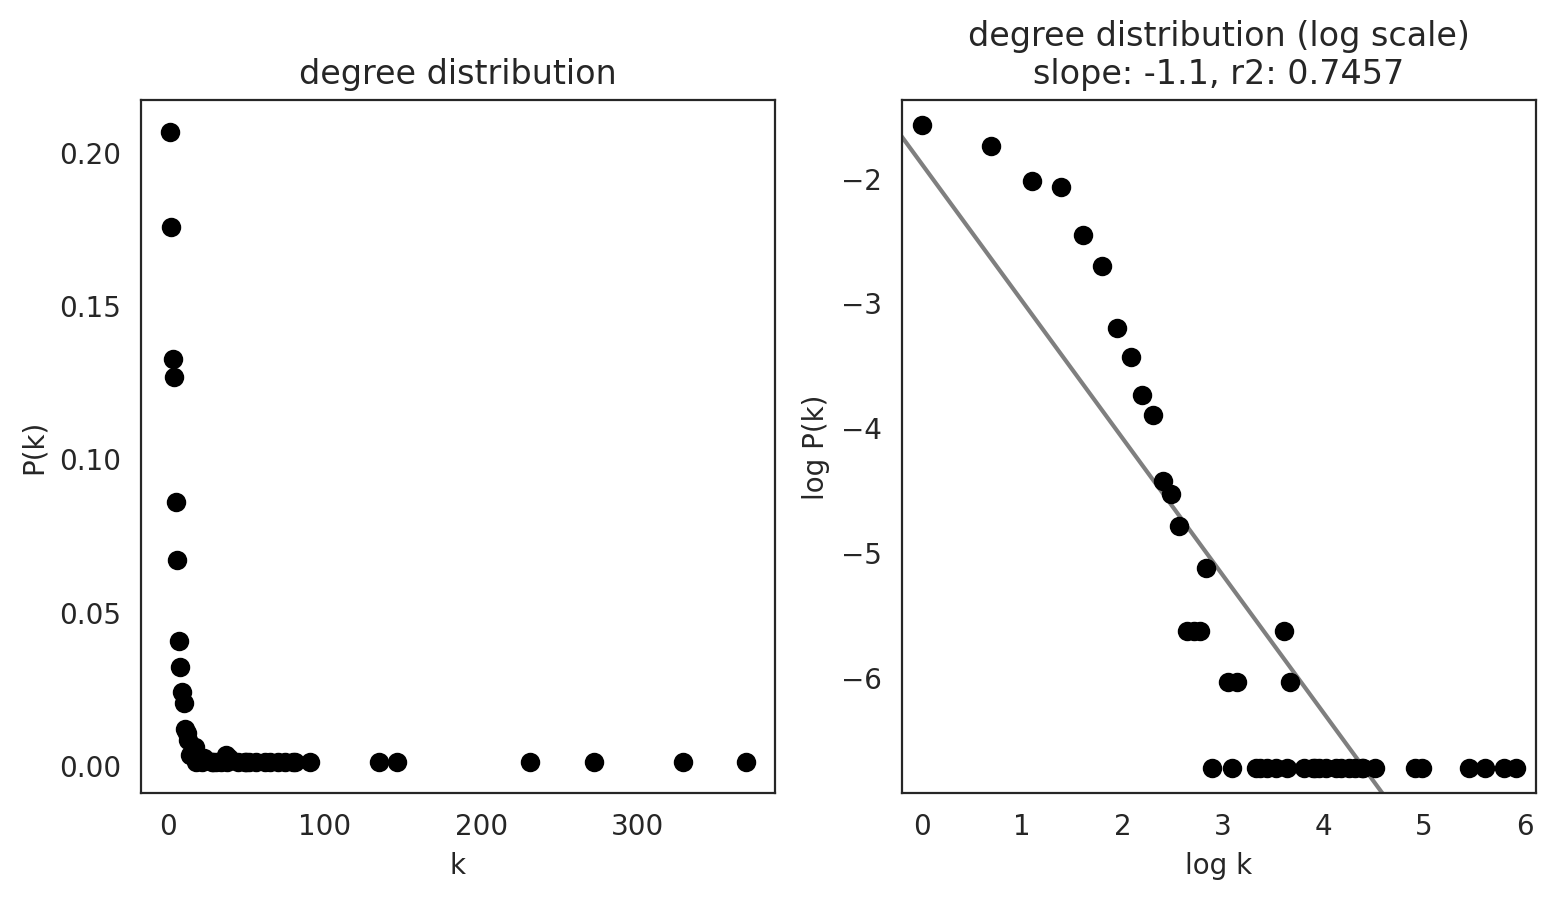

C8


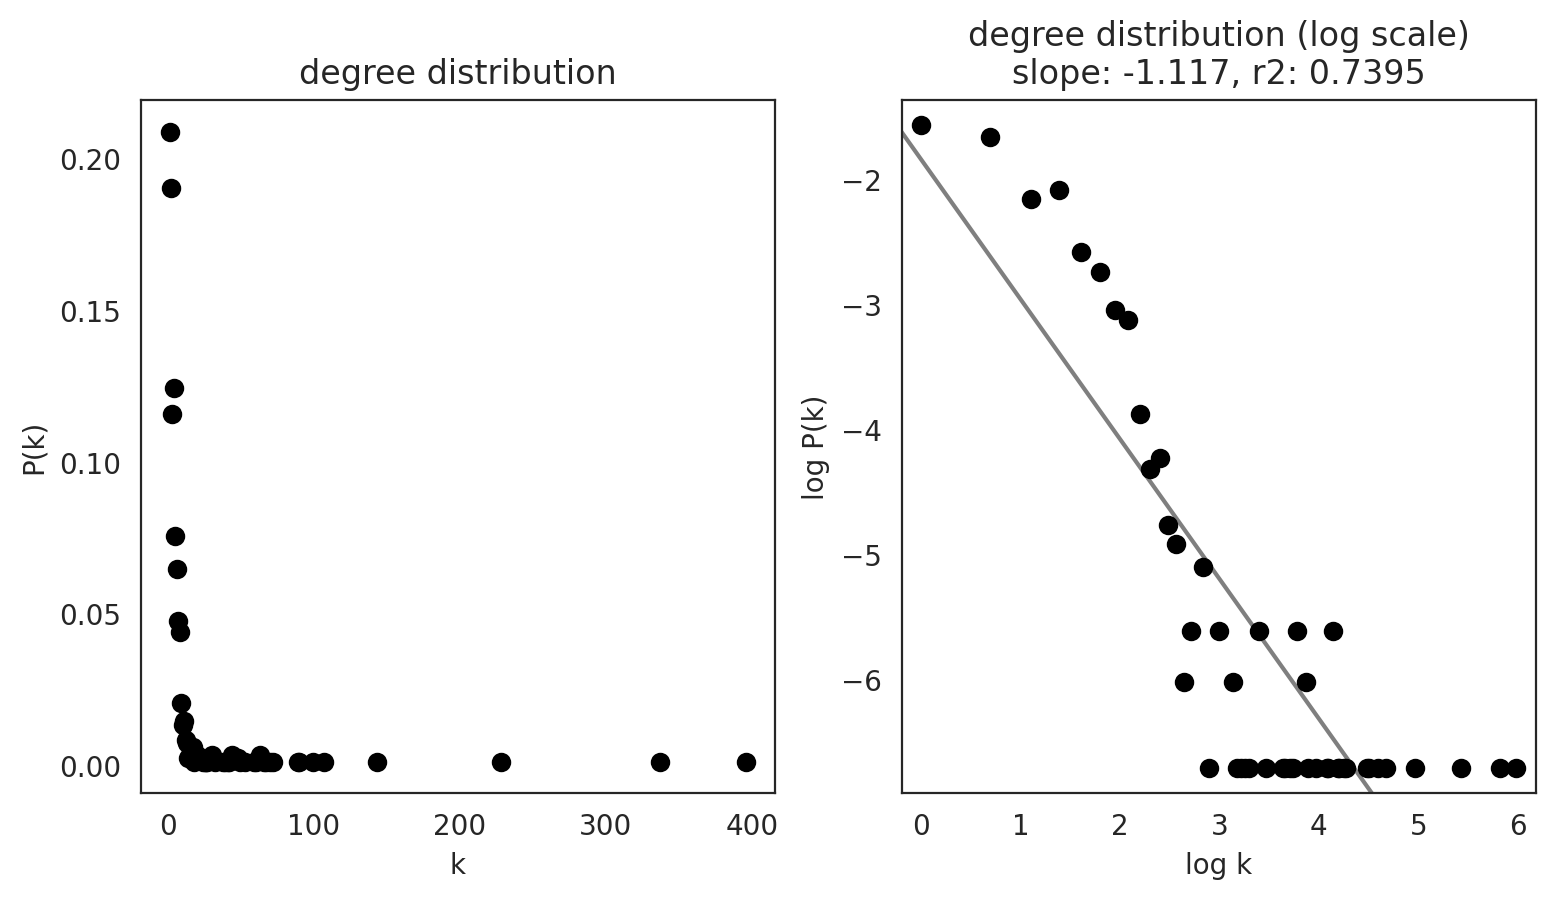

C9


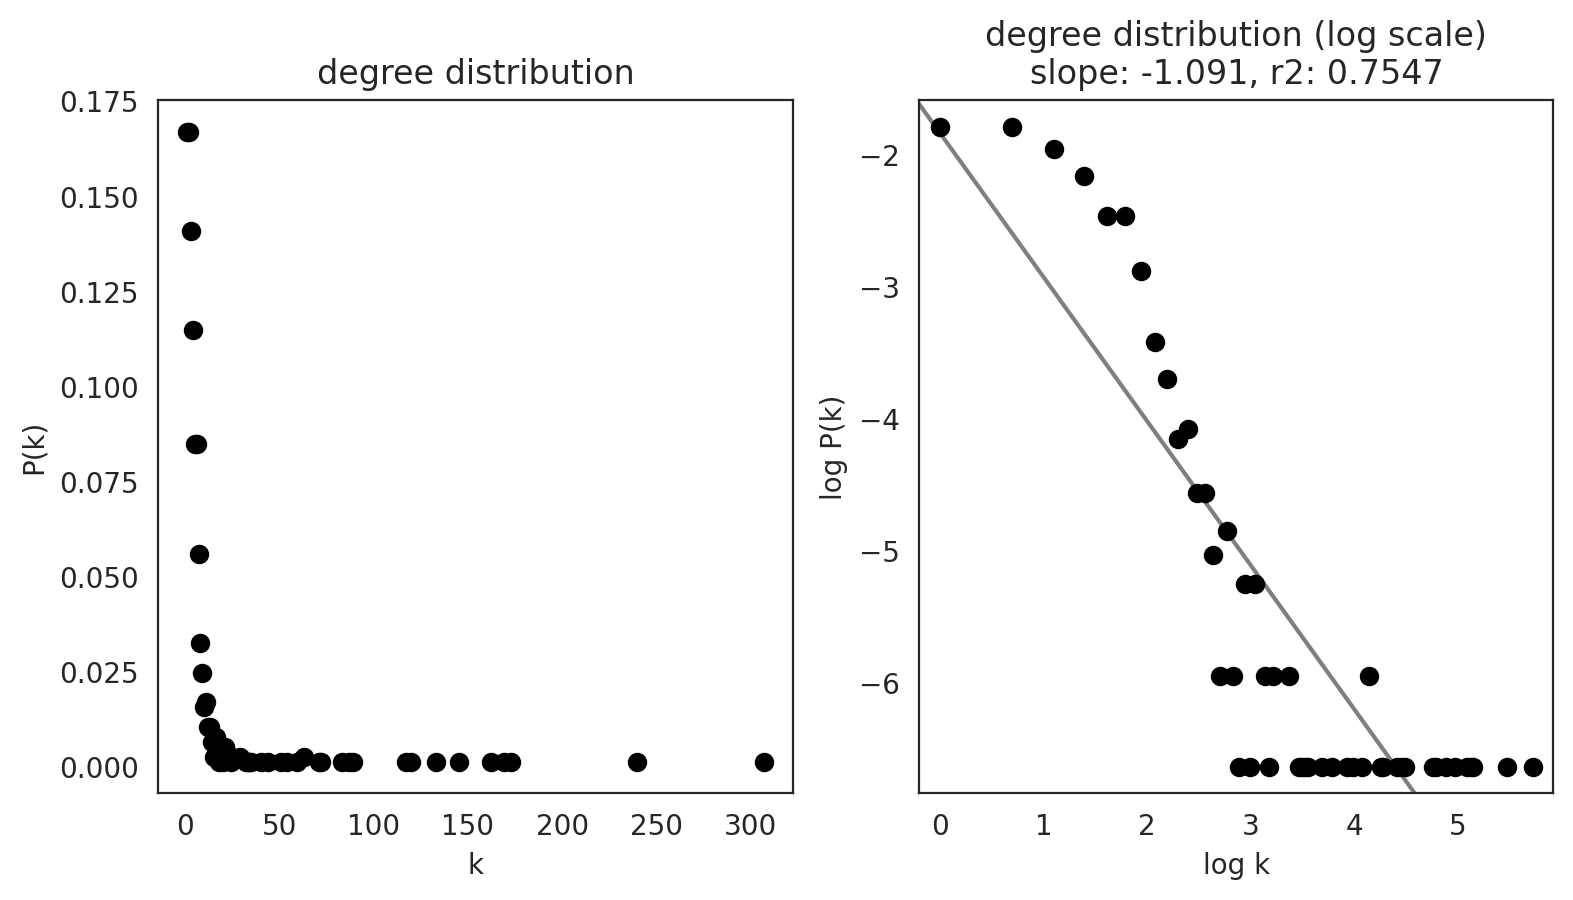

In [33]:
links.plot_degree_distributions(plot_model=True)

In [34]:
# Calculate network scores.
links.get_network_score()

In [35]:
links.merged_score.head()

,degree_all,degree_centrality_all,degree_in,degree_centrality_in,degree_out,degree_centrality_out,betweenness_centrality,eigenvector_centrality,cluster
ELK1,71,0.085439,0,0.000000,71,0.085439,0.0,0.207303,C0
SPRR3,8,0.009627,8,0.009627,0,0.000000,0.0,0.231288,C0
JDP2,71,0.085439,0,0.000000,71,0.085439,0.0,0.421764,C0
KRTDAP,9,0.010830,9,0.010830,0,0.000000,0.0,0.601630,C0
SP2,254,0.305656,6,0.007220,248,0.298436,2056.0,1.000000,C0


In [36]:
# Save Links object.
links.to_hdf5(file_path="data/4f/links.mal_hg38.filtered.celloracle.links")

In [37]:
links = co.load_hdf5(file_path="data/4f/links.mal_hg38.filtered.celloracle.links")

In [38]:
df = links.merged_score.query("cluster=='C6'").copy()
df = df[df['degree_centrality_out'] > 0]   # TF만, 73개
metrics = ['degree_centrality_out', 'eigenvector_centrality']
ranks = df[metrics].rank(ascending=False)
df['borda'] = ranks.mean(axis=1)
df.sort_values('borda').head(20)

,degree_all,degree_centrality_all,degree_in,degree_centrality_in,degree_out,degree_centrality_out,betweenness_centrality,eigenvector_centrality,cluster,borda
POU2F2,242,0.271605,5,0.005612,237,0.265993,1832.0,1.000000,C6,1.50
ZEB1,241,0.270483,7,0.007856,234,0.262626,6499.0,0.862231,C6,2.50
KLF2,248,0.278339,8,0.008979,240,0.269360,5177.0,0.789888,C6,2.50
KLF12,200,0.224467,6,0.006734,194,0.217733,4016.0,0.802772,C6,4.00
EGR1,223,0.250281,5,0.005612,218,0.244669,3896.0,0.767029,C6,4.50
POU5F1,131,0.147026,0,0.000000,131,0.147026,0.0,0.402114,C6,7.50
TEAD2,136,0.152637,0,0.000000,136,0.152637,0.0,0.393321,C6,8.00
EBF1,117,0.131313,8,0.008979,109,0.122334,2402.0,0.400253,C6,8.50
NFE2,141,0.158249,0,0.000000,141,0.158249,0.0,0.326661,C6,8.50
ID1,74,0.083053,8,0.008979,66,0.074074,888.0,0.409769,C6,10.00


In [39]:
df.sort_values('borda').head(20).index

Index(['POU2F2', 'ZEB1', 'KLF2', 'KLF12', 'EGR1', 'POU5F1', 'TEAD2', 'EBF1',
       'NFE2', 'ID1', 'SPI1', 'E2F3', 'BATF', 'SP2', 'FLI1', 'NFATC4', 'JDP2',
       'NR4A3', 'NFATC2', 'NR4A1'],
      dtype='object')

C6: 72 TFs out of 892 genes in the network


2026-08-12 13:24:28,753 - INFO - maxp pruned
2026-08-12 13:24:28,765 - INFO - cmap pruned
2026-08-12 13:24:28,767 - INFO - kern dropped
2026-08-12 13:24:28,768 - INFO - post pruned
2026-08-12 13:24:28,770 - INFO - FFTM dropped
2026-08-12 13:24:28,773 - INFO - GPOS pruned
2026-08-12 13:24:28,778 - INFO - GSUB pruned
2026-08-12 13:24:28,786 - INFO - glyf pruned
2026-08-12 13:24:28,788 - INFO - Added gid0 to subset
2026-08-12 13:24:28,789 - INFO - Added first four glyphs to subset
2026-08-12 13:24:28,790 - INFO - Closing glyph list over 'MATH': 50 glyphs before
2026-08-12 13:24:28,790 - INFO - Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'X', 'Y', 'Z', 'a', 'c', 'd', 'e', 'five', 'four', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'period', 'r', 's', 'six', 'space', 't', 'three', 'two', 'underscore', 'y', 'zero']
2026-08-12 13:24:28,792 - INFO - Glyph IDs:   [0, 1, 2, 3, 17, 19, 20, 21, 2

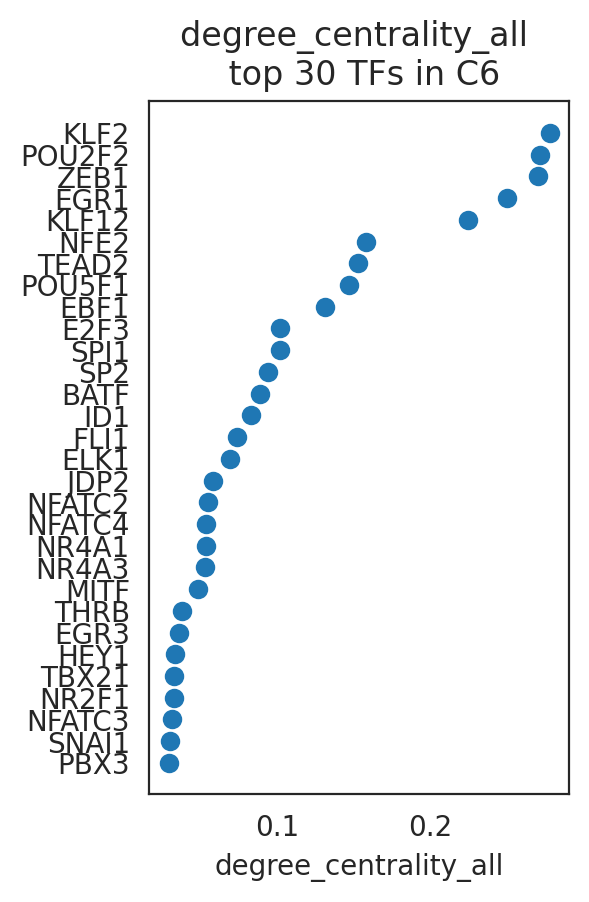

2026-08-12 13:24:29,207 - INFO - maxp pruned
2026-08-12 13:24:29,217 - INFO - cmap pruned
2026-08-12 13:24:29,219 - INFO - kern dropped
2026-08-12 13:24:29,220 - INFO - post pruned
2026-08-12 13:24:29,220 - INFO - FFTM dropped
2026-08-12 13:24:29,223 - INFO - GPOS pruned
2026-08-12 13:24:29,227 - INFO - GSUB pruned
2026-08-12 13:24:29,235 - INFO - glyf pruned
2026-08-12 13:24:29,236 - INFO - Added gid0 to subset
2026-08-12 13:24:29,237 - INFO - Added first four glyphs to subset
2026-08-12 13:24:29,238 - INFO - Closing glyph list over 'MATH': 50 glyphs before
2026-08-12 13:24:29,239 - INFO - Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'X', 'Z', 'a', 'c', 'd', 'e', 'five', 'four', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'period', 'r', 's', 'seven', 'six', 'space', 't', 'three', 'two', 'underscore', 'y', 'zero']
2026-08-12 13:24:29,241 - INFO - Glyph IDs:   [0, 1, 2, 3, 17, 19, 20, 2

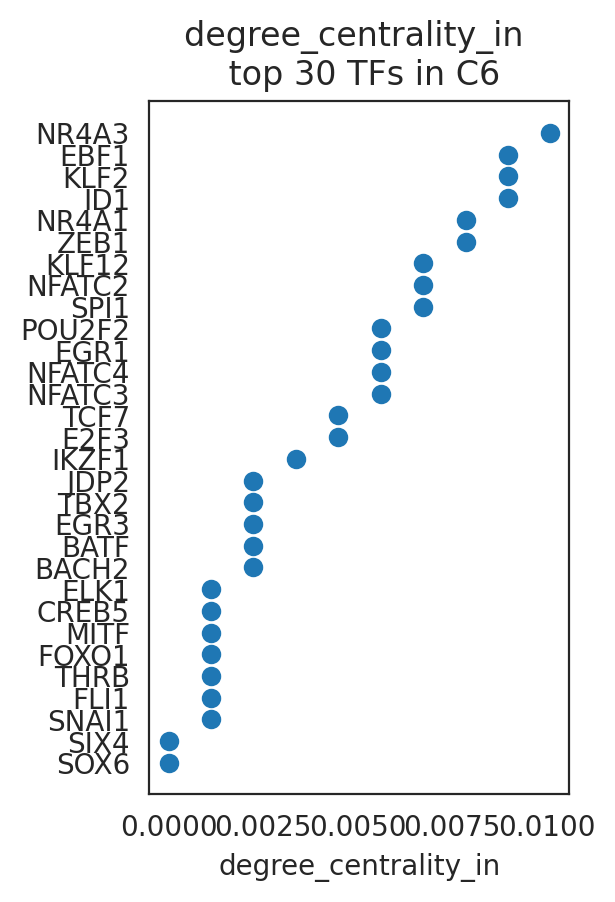

2026-08-12 13:24:29,690 - INFO - maxp pruned
2026-08-12 13:24:29,701 - INFO - cmap pruned
2026-08-12 13:24:29,702 - INFO - kern dropped
2026-08-12 13:24:29,703 - INFO - post pruned
2026-08-12 13:24:29,704 - INFO - FFTM dropped
2026-08-12 13:24:29,706 - INFO - GPOS pruned
2026-08-12 13:24:29,711 - INFO - GSUB pruned
2026-08-12 13:24:29,721 - INFO - glyf pruned
2026-08-12 13:24:29,723 - INFO - Added gid0 to subset
2026-08-12 13:24:29,724 - INFO - Added first four glyphs to subset
2026-08-12 13:24:29,725 - INFO - Closing glyph list over 'MATH': 52 glyphs before
2026-08-12 13:24:29,725 - INFO - Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'V', 'X', 'Y', 'Z', 'a', 'c', 'd', 'e', 'five', 'four', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'period', 'r', 's', 'six', 'space', 't', 'three', 'two', 'u', 'underscore', 'y', 'zero']
2026-08-12 13:24:29,727 - INFO - Glyph IDs:   [0, 1, 2, 3, 17, 19,

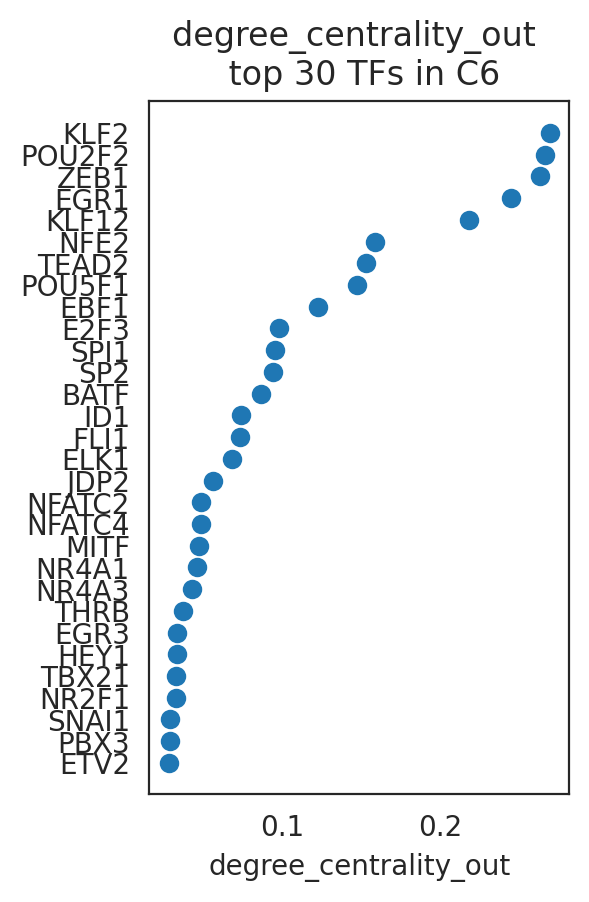

2026-08-12 13:24:30,138 - INFO - maxp pruned
2026-08-12 13:24:30,149 - INFO - cmap pruned
2026-08-12 13:24:30,150 - INFO - kern dropped
2026-08-12 13:24:30,151 - INFO - post pruned
2026-08-12 13:24:30,152 - INFO - FFTM dropped
2026-08-12 13:24:30,155 - INFO - GPOS pruned
2026-08-12 13:24:30,159 - INFO - GSUB pruned
2026-08-12 13:24:30,167 - INFO - glyf pruned
2026-08-12 13:24:30,169 - INFO - Added gid0 to subset
2026-08-12 13:24:30,170 - INFO - Added first four glyphs to subset
2026-08-12 13:24:30,171 - INFO - Closing glyph list over 'MATH': 49 glyphs before
2026-08-12 13:24:30,172 - INFO - Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'X', 'Z', 'a', 'b', 'c', 'e', 'five', 'four', 'i', 'l', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'r', 's', 'seven', 'six', 'space', 't', 'three', 'two', 'underscore', 'w', 'y', 'zero']
2026-08-12 13:24:30,173 - INFO - Glyph IDs:   [0, 1, 2, 3, 19, 20, 21, 22, 23, 24,

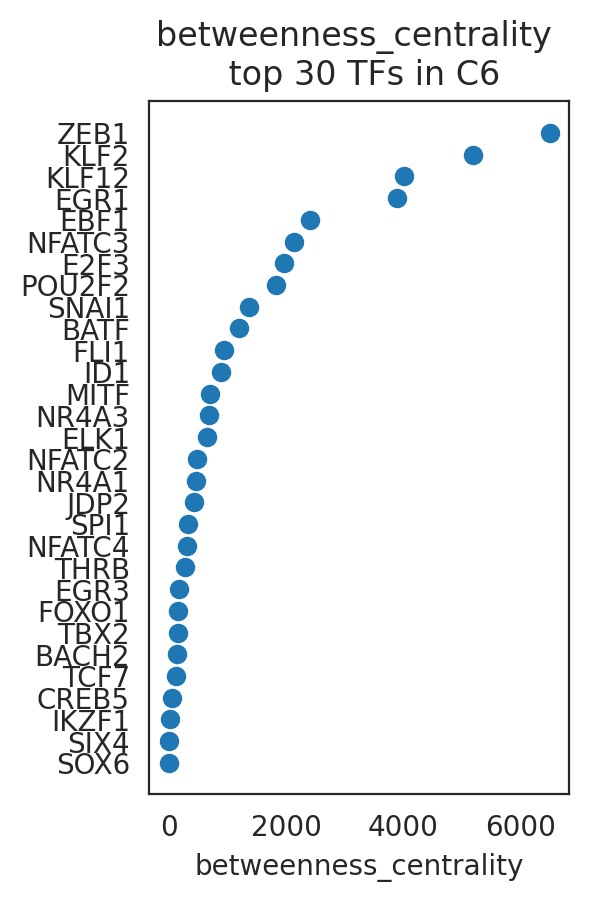

2026-08-12 13:24:30,603 - INFO - maxp pruned
2026-08-12 13:24:30,614 - INFO - cmap pruned
2026-08-12 13:24:30,615 - INFO - kern dropped
2026-08-12 13:24:30,616 - INFO - post pruned
2026-08-12 13:24:30,617 - INFO - FFTM dropped
2026-08-12 13:24:30,619 - INFO - GPOS pruned
2026-08-12 13:24:30,623 - INFO - GSUB pruned
2026-08-12 13:24:30,635 - INFO - glyf pruned
2026-08-12 13:24:30,637 - INFO - Added gid0 to subset
2026-08-12 13:24:30,638 - INFO - Added first four glyphs to subset
2026-08-12 13:24:30,639 - INFO - Closing glyph list over 'MATH': 50 glyphs before
2026-08-12 13:24:30,640 - INFO - Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'X', 'Y', 'Z', 'a', 'c', 'e', 'five', 'four', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'period', 'r', 's', 'seven', 'six', 'space', 't', 'three', 'two', 'underscore', 'v', 'y', 'zero']
2026-08-12 13:24:30,641 - INFO - Glyph IDs:   [0, 1, 2, 3, 17, 19, 20, 2

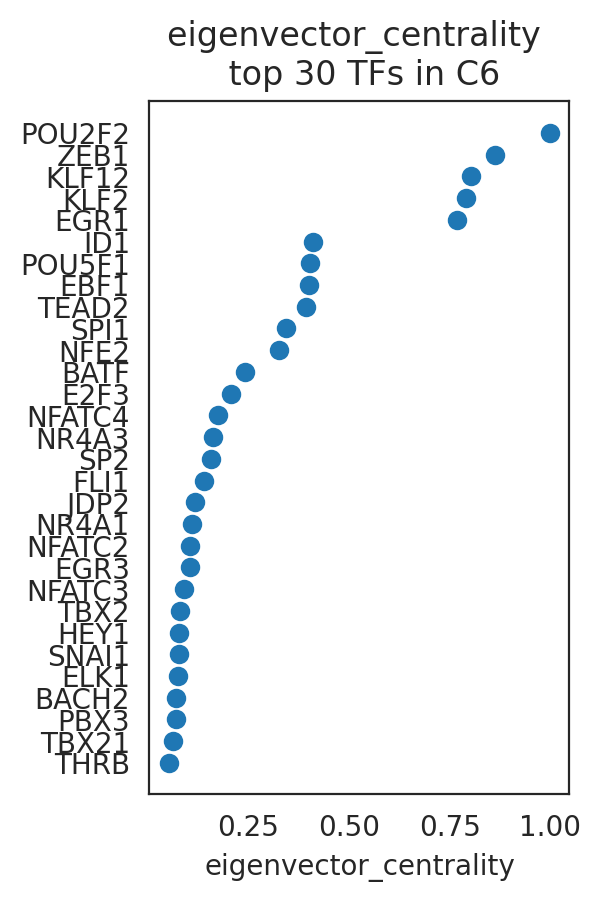

In [ ]:
# rank plot regarding only TFs
cluster_name = 'C6'
n_gene = 30

df_cl = links.merged_score.query("cluster == @cluster_name").copy()
df_tf = df_cl[df_cl['degree_centrality_out'] > 0]  
df_tf = df_tf[~df_tf.index.isin(['ITGB2', 'CREB3L42'])]
print(f"{cluster_name}: {len(df_tf)} TFs out of {len(df_cl)} genes in the network")

save_dir = f"{save_folder}/ranked_score_TF_only"
os.makedirs(save_dir, exist_ok=True)

for value in ['degree_centrality_all', 'degree_centrality_in', 'degree_centrality_out',
              'betweenness_centrality', 'eigenvector_centrality']:
    res = df_tf[value].sort_values(ascending=False)[:n_gene]

    fig = plt.figure()
    plt.scatter(res.values, range(len(res)))
    plt.yticks(range(len(res)), res.index.values)
    plt.xlabel(value)
    plt.title(f"{value} \n top {n_gene} TFs in {cluster_name}")
    plt.gca().invert_yaxis()
    plt.subplots_adjust(left=0.5, right=0.85)

    fig.savefig(f"{save_dir}/ranked_values_TFonly_{value}_in_{cluster_name}.pdf", transparent=True)
    plt.show()

In [46]:
## specificity score
STATES = ['C4', 'C6', 'C8', 'C9']
TARGET = 'C6'
OTHERS = [s for s in STATES if s != TARGET]
METRICS = ['eigenvector_centrality', 'degree_centrality_out']
TOP_N = 10

merged = links.merged_score
merged = merged[~merged.index.isin(['ITGB2', 'CREB3L42'])]

tf_union = set()
for s in STATES:
    sub = merged[merged.cluster == s]
    tf_union.update(sub[sub['degree_centrality_out'] > 0].index)
tf_union = sorted(tf_union)

sub_states = merged[merged.cluster.isin(STATES)]
pivots = {m: sub_states.pivot_table(index=sub_states.index, columns='cluster', values=m).reindex(tf_union).fillna(0.0)
          for m in METRICS}

z_scores = pd.DataFrame(index=tf_union)
for m in METRICS:
    piv = pivots[m]
    std_dist = piv[OTHERS].std(axis=1)
    s0 = np.percentile(std_dist[std_dist > 0], 25)
    delta = piv[TARGET] - piv[OTHERS].mean(axis=1)
    z_scores[m] = delta / (std_dist + s0)
z_scores.head()

,eigenvector_centrality,degree_centrality_out
BACH2,0.137342,-0.613520
BATF,2.561719,0.939050
BCL6,-1.319495,-1.088303
CREB3L4,-0.684911,-0.825759
CREB5,-1.609351,-1.689698


2026-09-11 13:31:01,057 - INFO - maxp pruned
2026-09-11 13:31:01,069 - INFO - cmap pruned
2026-09-11 13:31:01,072 - INFO - kern dropped
2026-09-11 13:31:01,073 - INFO - post pruned
2026-09-11 13:31:01,074 - INFO - FFTM dropped
2026-09-11 13:31:01,077 - INFO - GPOS pruned
2026-09-11 13:31:01,082 - INFO - GSUB pruned
2026-09-11 13:31:01,476 - INFO - glyf pruned
2026-09-11 13:31:01,478 - INFO - Added gid0 to subset
2026-09-11 13:31:01,479 - INFO - Added first four glyphs to subset
2026-09-11 13:31:01,480 - INFO - Closing glyph list over 'MATH': 60 glyphs before
2026-09-11 13:31:01,481 - INFO - Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'V', 'X', 'Z', 'a', 'c', 'd', 'e', 'eight', 'f', 'five', 'four', 'g', 'hyphen', 'i', 'k', 'l', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'r', 's', 'seven', 'six', 'slash', 'space', 't', 'three', 'two', 'u', 'underscore', 'v', 'y', 'z', 'z

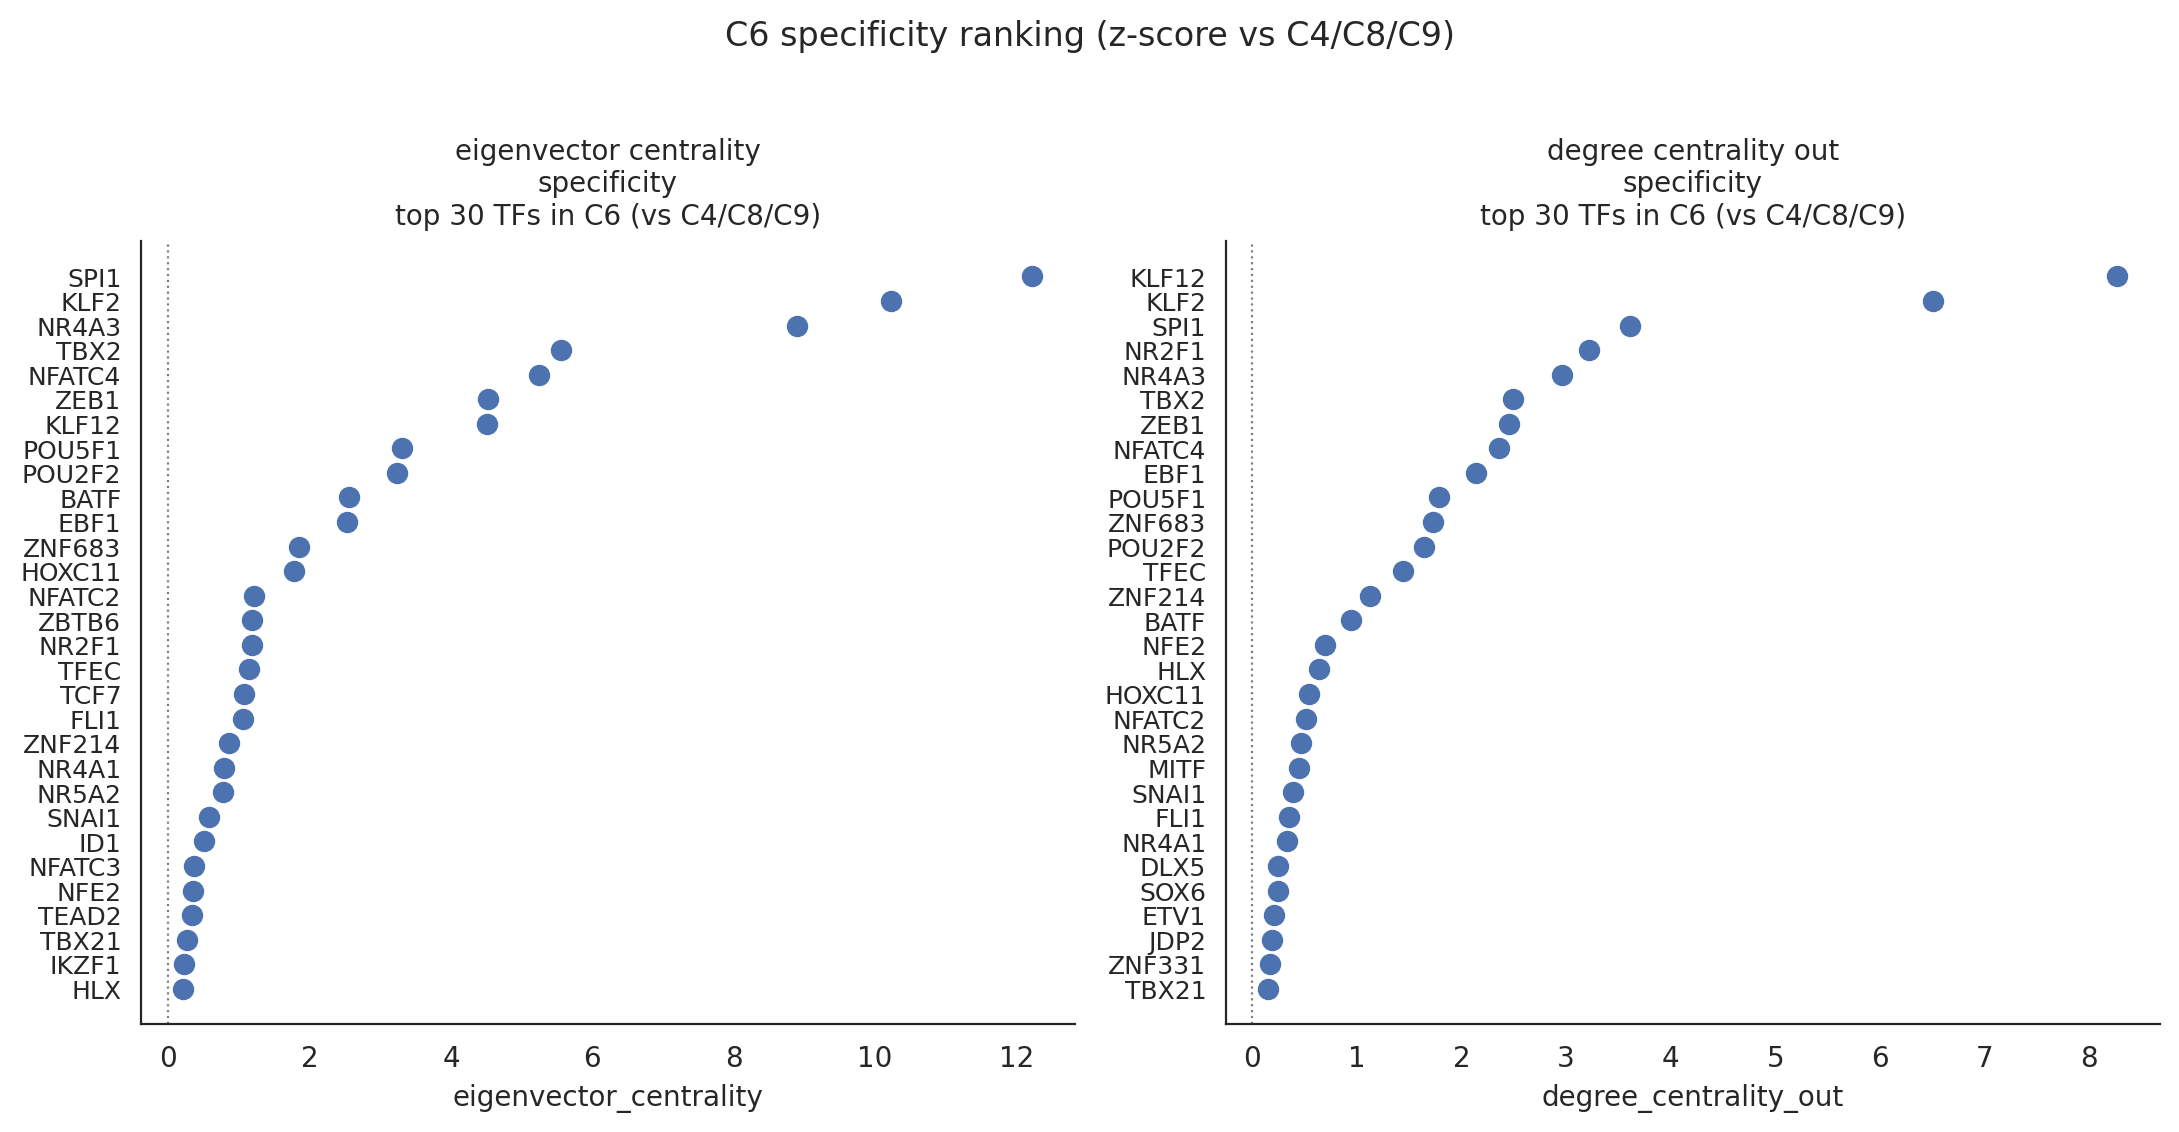

In [ ]:
# ==== specificity score (top20 rank plot) ====
N_TOP = 30
final_tfs = set(z_scores.index)

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
titles = {'eigenvector_centrality': 'eigenvector centrality\nspecificity',
          'degree_centrality_out': 'degree centrality out\nspecificity'}

for ax, m in zip(axes, METRICS):
    top = z_scores[m].sort_values(ascending=True).tail(N_TOP)
    colors = ['#4C72B0']
    ax.scatter(top.values, range(len(top)), c=colors, s=45, zorder=3)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top.index, fontsize=9)
    ax.axvline(0, color='grey', linewidth=0.8, linestyle=':')
    ax.set_xlabel(m)
    ax.set_title(f"{titles[m]}\ntop {N_TOP} TFs in C6 (vs C4/C8/C9)", fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('C6 specificity ranking (z-score vs C4/C8/C9)', fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig(f'{save_folder}/C6_specificity_zscore_rankplot.pdf', bbox_inches='tight')
plt.show()

In [48]:
### save C6-specific GRNs
cluster_name = 'C6'
filtered_links_df = links.filtered_links[cluster_name]
filtered_links_df.head()

,source,target,coef_mean,coef_abs,p,-logp
5243,NFIL3,COL3A1,0.201523,0.201523,2.169951e-11,10.663550
20033,POU5F1,POSTN,-0.184856,0.184856,4.905576e-19,18.309310
12132,BATF,INHBA,0.180201,0.180201,1.974504e-19,18.704542
25259,TEAD2,TALAM1,-0.178106,0.178106,2.285302e-15,14.641056
14889,EGR1,LUM,0.167514,0.167514,7.537412e-18,17.122778


In [49]:
filtered_links_df.to_csv('data/4f/hg38_c6_tf.csv', index=False)

In [ ]:
### In silico TF perturbation 

In [50]:
oracle = co.load_hdf5("data/4f/singlecell_mal_hg38.celloracle.oracle")

In [51]:
links = co.load_hdf5(file_path="data/4f/links.mal_hg38.filtered.celloracle.links")

In [53]:
base_GRN = pd.read_parquet('data/4f/base_GRN_dataframe.parquet')
base_GRN

,peak_id,gene_short_name,9430076C15RIK,AC002126.6,AC012531.1,AC226150.2,AFP,AHR,AHRR,AIRE,...,ZNF784,ZNF8,ZNF816,ZNF85,ZSCAN10,ZSCAN16,ZSCAN22,ZSCAN26,ZSCAN31,ZSCAN4
0,chr10_100009743_100010244,DNMBP,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,chr10_100081652_100082153,CPN1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
2,chr10_100185812_100186313,ERLIN1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,chr10_100186342_100186843,ERLIN1,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,chr10_100229354_100229855,CHUK,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41367,chrX_9785550_9786051,SHROOM2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41368,chrX_9786109_9786610,SHROOM2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41369,chrX_9911033_9911534,SHROOM2,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
41370,chrX_9911535_9912036,SHROOM2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [54]:
links.filter_links()
oracle.get_cluster_specific_TFdict_from_Links(links_object=links)
oracle.fit_GRN_for_simulation(alpha=10,
                              use_cluster_specific_TFdict=True)

  0%|          | 0/10 [00:00<?, ?it/s]

In [ ]:
# SIMULTAE TF PERTURBATION

In [57]:
cluster_column = "clusters"
cols = {'C0' : "#A6CEE3", 
        'C1' : "#1F78B4" ,
        'C2' :"#B2DF8A" ,
        'C3' :"#33A02C",
        'C4' :"#FB9A99" ,
        'C5' :"#FDBF6F",
        'C6' :"#E31A1C", 
        'C7' :"#FF7F00",
        'C8' : "#CAB2D6",
        'C9' :"#6A3D9A"}
cell_colors = oracle.adata.obs[cluster_column].map(cols).values

if pd.isna(cell_colors).any():
    print("Warning: Some clusters are not defined in your 'cols' dictionary.")
    cell_colors = np.nan_to_num(cell_colors, copy=False, nan="#CCCCCC")

In [58]:
gois = ['EGR1','POU2F2','FLI1','NFATC2']

In [61]:
for goi in gois :
    # if not goi in base_GRN.columns : continue
    oracle.simulate_shift(perturb_condition={goi: 0.0},
                      n_propagation=3)
    
    # Get transition probability
    oracle.estimate_transition_prob(n_neighbors=200,
                                    knn_random=True,
                                    sampled_fraction=1)

    # Calculate embedding
    oracle.calculate_embedding_shift(sigma_corr=0.05)

    fig, ax = plt.subplots(1, 2,  figsize=[13, 6])

    scale = 20
    # Show quiver plot
    oracle.plot_quiver(scale=scale, ax=ax[0], color = cell_colors)
    ax[0].set_title(f"Simulated cell identity shift vector: {goi} KO")

    # Show quiver plot that was calculated with randomized graph.
    oracle.plot_quiver_random(scale=scale, ax=ax[1], color = cell_colors)
    ax[1].set_title(f"Randomized simulation vector")

    # plt.show()
    plt.savefig(f"figures/4f_Mal_Cell_Shift_Simulation_{goi}_KO.pdf", bbox_inches='tight', dpi=300) 
    plt.close(fig) 

2026-09-11 13:37:59,539 - INFO - maxp pruned
2026-09-11 13:37:59,552 - INFO - cmap pruned
2026-09-11 13:37:59,553 - INFO - kern dropped
2026-09-11 13:37:59,554 - INFO - post pruned
2026-09-11 13:37:59,555 - INFO - FFTM dropped
2026-09-11 13:37:59,557 - INFO - GPOS pruned
2026-09-11 13:37:59,562 - INFO - GSUB pruned
2026-09-11 13:37:59,573 - INFO - glyf pruned
2026-09-11 13:37:59,575 - INFO - Added gid0 to subset
2026-09-11 13:37:59,576 - INFO - Added first four glyphs to subset
2026-09-11 13:37:59,577 - INFO - Closing glyph list over 'MATH': 30 glyphs before
2026-09-11 13:37:59,578 - INFO - Glyph names: ['.notdef', '.null', 'E', 'G', 'K', 'O', 'R', 'S', 'a', 'c', 'colon', 'd', 'e', 'f', 'h', 'i', 'l', 'm', 'n', 'nonmarkingreturn', 'o', 'one', 'r', 's', 'space', 't', 'u', 'v', 'y', 'z']
2026-09-11 13:37:59,579 - INFO - Glyph IDs:   [0, 1, 2, 3, 20, 29, 40, 42, 46, 50, 53, 54, 68, 70, 71, 72, 73, 75, 76, 79, 80, 81, 82, 85, 86, 87, 88, 89, 92, 93]
2026-09-11 13:37:59,581 - INFO - Closed 

In [ ]:
### save development flow

In [62]:
from celloracle.applications import Gradient_calculator

# Instantiate Gradient calculator object
gradient = Gradient_calculator(oracle_object=oracle, pseudotime_key="latent_time")

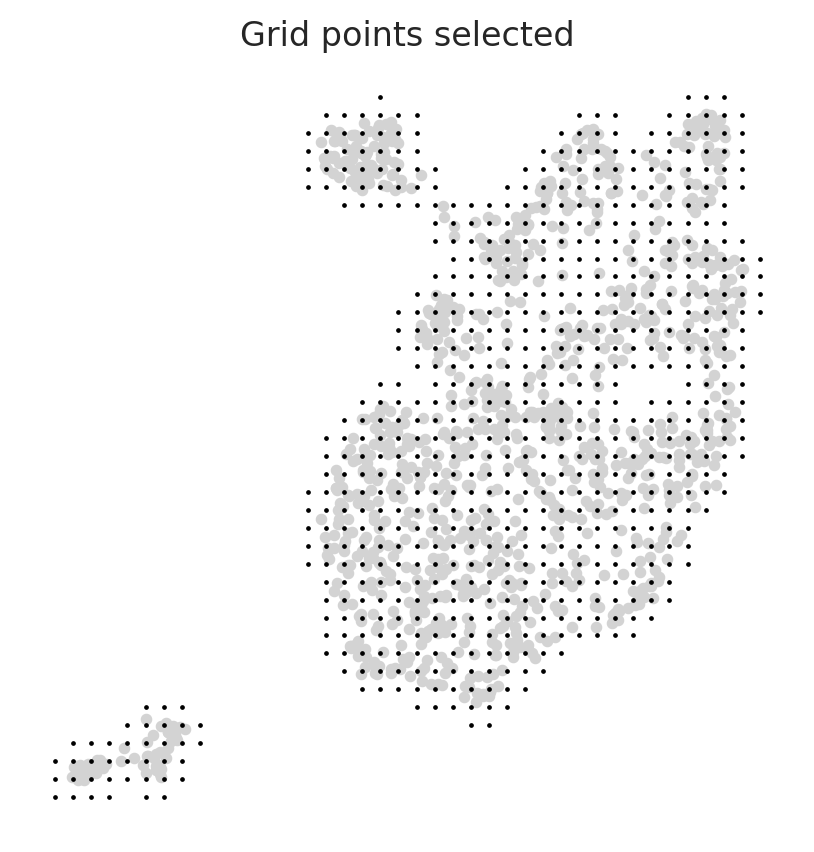

In [64]:
gradient.calculate_p_mass(smooth=0.8, n_grid=40, n_neighbors=200)
gradient.calculate_mass_filter(min_mass=1, plot=True)

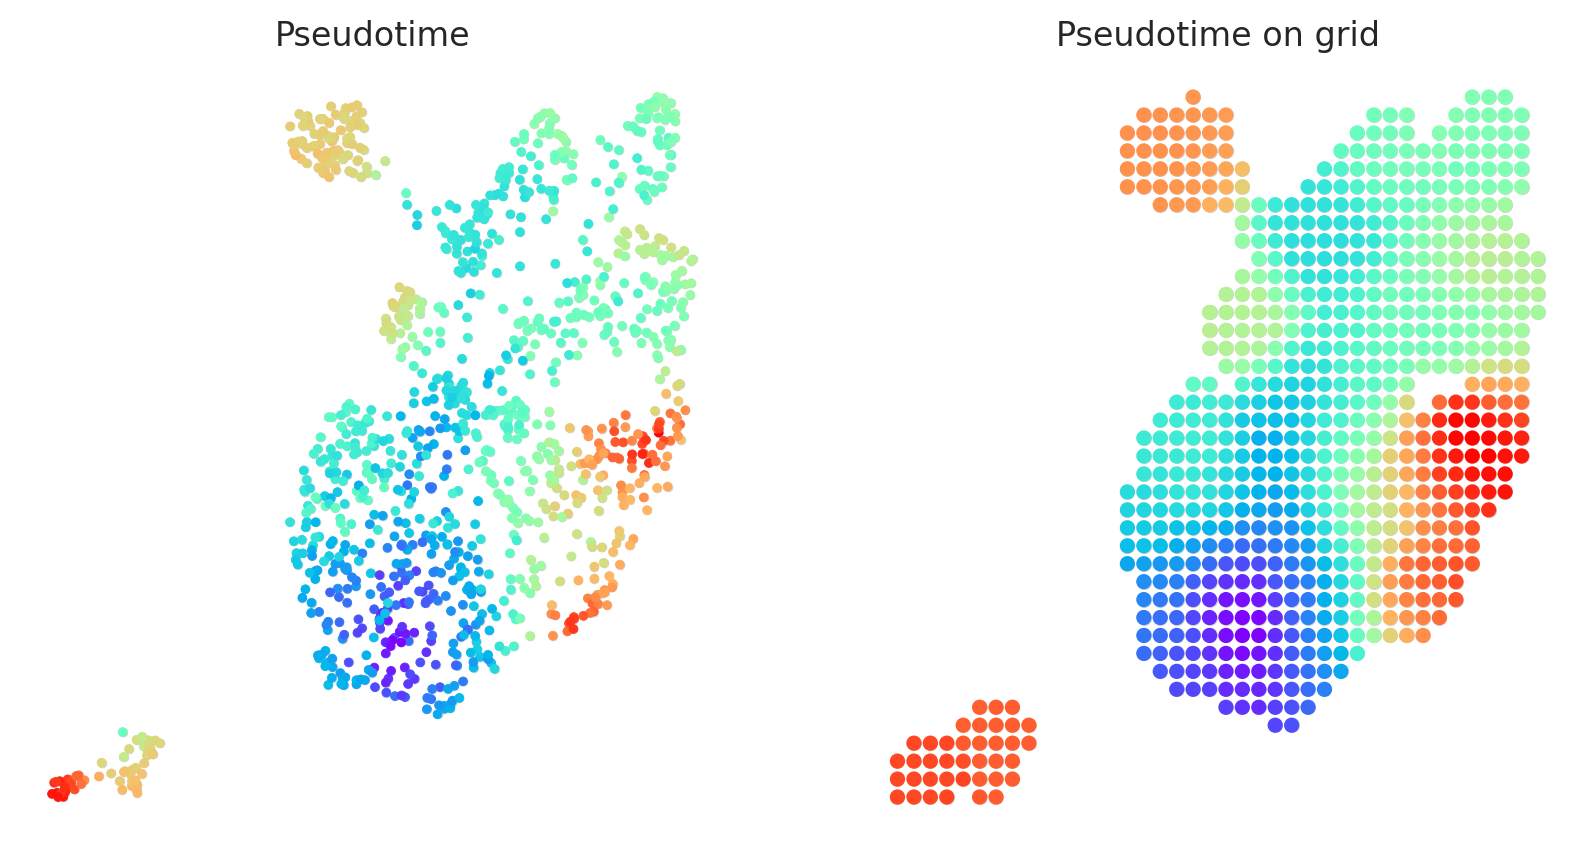

In [65]:
gradient.transfer_data_into_grid(args={"method": "knn", "n_knn":50}, plot=True)

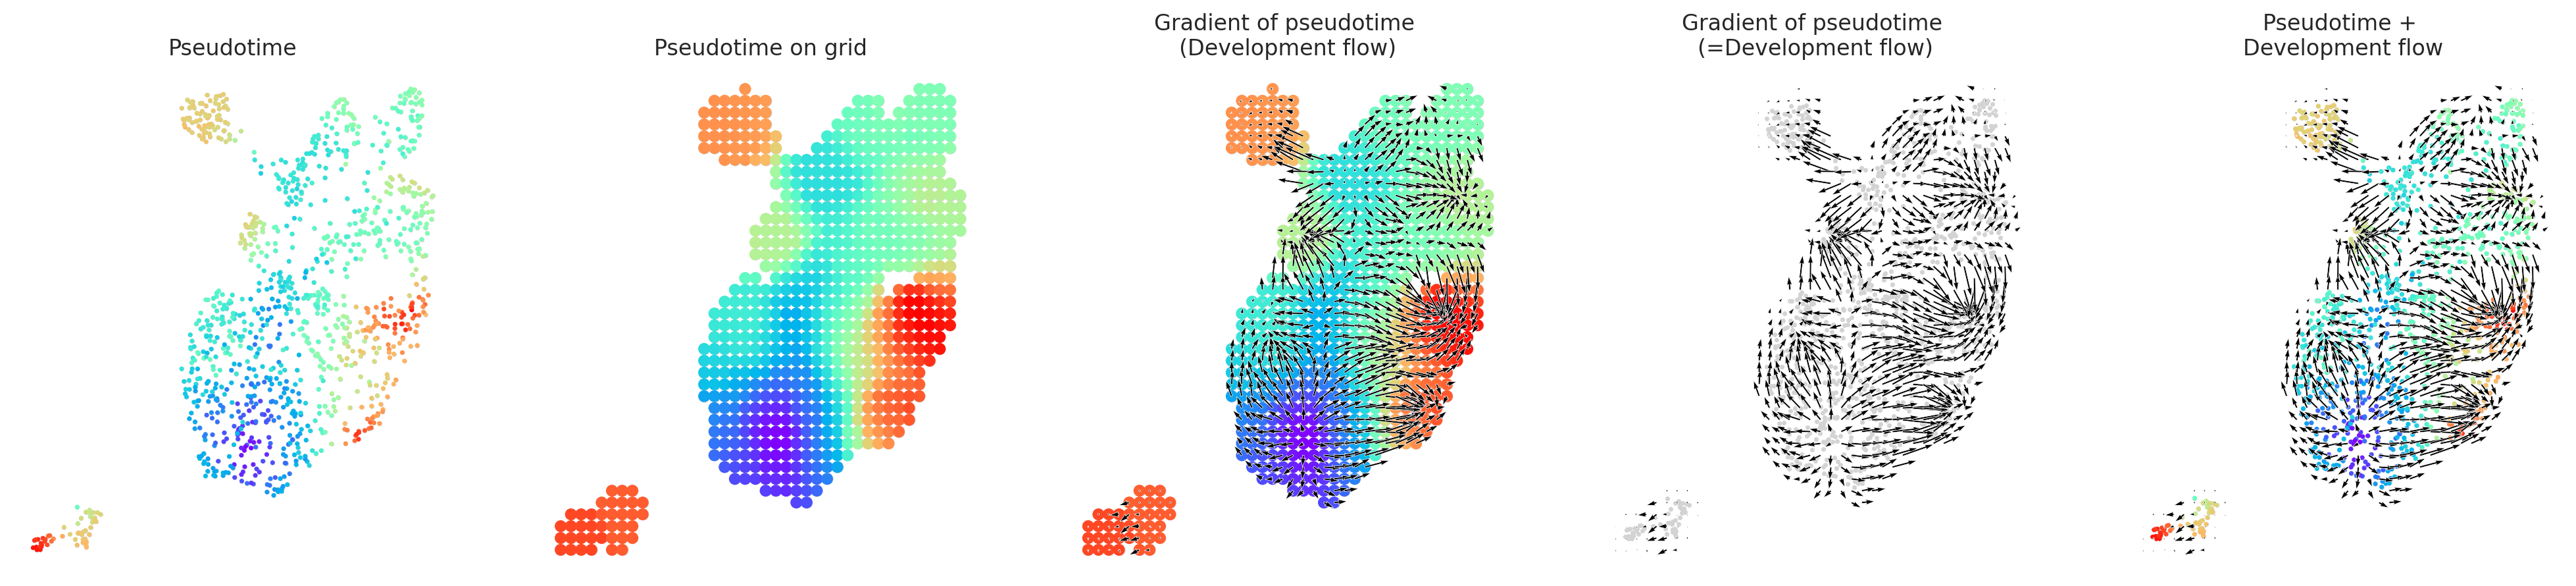

In [66]:
# Calculate graddient
gradient.calculate_gradient()

# Show results
scale_dev = 30
gradient.visualize_results(scale=scale_dev, s=5)

In [67]:
# Visualize results
fig, ax = plt.subplots(figsize=[6, 6])
gradient.plot_dev_flow_on_grid(scale=scale_dev, ax=ax)

plt.savefig("figures/4f_mal_development_flow.pdf", bbox_inches='tight', dpi=300) 
plt.close(fig) 